In [22]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from itertools import product

In [4]:
df = pd.read_csv("../EDA/final_model.csv")

In [5]:
df["Start Date"] = pd.to_datetime(df["Start Date"], errors="coerce")
df = df.dropna(subset=["Start Date", "Runs"])
df = df.sort_values("Start Date").reset_index(drop=True)

In [6]:
df.head()

,Runs,Pos,Inns,Ground,Start Date,NotOut,Rolling5,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,Opposition_v England,Opposition_v Ireland,Opposition_v Netherlands,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe
0,37,2,2,Dambulla,2008-08-20,0,12.000000,12.000000,0,0,0,0,0,0,0,0,1,0,0,0
1,25,1,1,Colombo (RPS),2008-08-24,0,24.500000,24.500000,0,0,0,0,0,0,0,0,1,0,0,0
2,54,1,1,Colombo (RPS),2008-08-27,0,24.666667,24.666667,0,0,0,0,0,0,0,0,1,0,0,0
3,31,1,2,Colombo (RPS),2008-08-29,0,32.000000,32.000000,0,0,0,0,0,0,0,0,1,0,0,0
4,2,7,1,Colombo (RPS),2009-09-14,1,31.800000,31.800000,0,0,0,0,0,0,0,0,1,0,0,0


In [8]:
print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset shape: (298, 20)
['Runs', 'Pos', 'Inns', 'Ground', 'Start Date', 'NotOut', 'Rolling5', 'Rolling10', 'Opposition_v Australia', 'Opposition_v Bangladesh', 'Opposition_v England', 'Opposition_v Ireland', 'Opposition_v Netherlands', 'Opposition_v New Zealand', 'Opposition_v Pakistan', 'Opposition_v South Africa', 'Opposition_v Sri Lanka', 'Opposition_v U.A.E.', 'Opposition_v West Indies', 'Opposition_v Zimbabwe']


In [9]:
opposition_cols = [
    col for col in df.columns
    if col.startswith("Opposition_")
]

In [10]:
opposition_cols

['Opposition_v Australia',
 'Opposition_v Bangladesh',
 'Opposition_v England',
 'Opposition_v Ireland',
 'Opposition_v Netherlands',
 'Opposition_v New Zealand',
 'Opposition_v Pakistan',
 'Opposition_v South Africa',
 'Opposition_v Sri Lanka',
 'Opposition_v U.A.E.',
 'Opposition_v West Indies',
 'Opposition_v Zimbabwe']

In [11]:
numeric_feats = ["Rolling5", "Rolling10"]
categorical_feats = ["Ground"]

features = numeric_feats + categorical_feats + opposition_cols

In [13]:
X = df[features]
y = df["Runs"]

In [19]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [20]:
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

In [21]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numeric_feats),
    ("ground", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
         , categorical_feats),
    (
        "opposition",
        SimpleImputer(strategy="most_frequent"),
        opposition_cols
    )
])

In [23]:
depths = [2, 3, 4, 5, 8, None]
min_leafs_sizes = [2, 3, 5, 8, 10]
min_split_sizes = [2, 5, 10, 20]

In [24]:
results = []
best_mae = float('inf')
best_params = None
best_model = None

In [27]:
for depth, leaf_size, split_size in product(
    depths, min_leafs_sizes, min_split_sizes
):
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf_size,
            min_samples_split=split_size,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf_size,
        "min_samples_split": split_size,
        "Validation_MAE": mae,
        "Validation_RMSE": rmse,
        "Validation_R2": r2,
    })

    if mae < best_mae:
        best_mae = mae
        best_params = {
            "max_depth": depth,
            "min_samples_leaf": leaf_size,
            "min_samples_split": split_size,
        }
        best_model = model


In [28]:
tuning_results = pd.DataFrame(results).sort_values("Validation_MAE")
print("Best parameters: ", best_params)
print("Best validation MAE: ", round(best_mae, 3))

Best parameters:  {'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best validation MAE:  34.473


In [29]:
tuning_results.head(10)

,max_depth,min_samples_leaf,min_samples_split,Validation_MAE,Validation_RMSE,Validation_R2
3,2.0,2,20,34.472704,41.222543,-0.273523
2,2.0,2,10,34.472704,41.222543,-0.273523
5,2.0,3,5,34.472704,41.222543,-0.273523
4,2.0,3,2,34.472704,41.222543,-0.273523
6,2.0,3,10,34.472704,41.222543,-0.273523
7,2.0,3,20,34.472704,41.222543,-0.273523
9,2.0,5,5,34.472704,41.222543,-0.273523
8,2.0,5,2,34.472704,41.222543,-0.273523
10,2.0,5,10,34.472704,41.222543,-0.273523
11,2.0,5,20,34.472704,41.222543,-0.273523


In [30]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

In [31]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        **best_params,
        random_state=42
    ))
])

In [32]:
final_model.fit(X_train_val, y_train_val)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ground', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different

In [33]:
test_predictions = final_model.predict(X_test)

In [34]:
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

In [35]:
print("Decision Tree Regression — Test Results")
print(f"MAE:  {test_mae:.3f}")
print(f"RMSE: {test_rmse:.3f}")
print(f"R²:   {test_r2:.3f}")

Decision Tree Regression — Test Results
MAE:  43.786
RMSE: 52.455
R²:   -0.296


In [37]:
import matplotlib.pyplot as plt

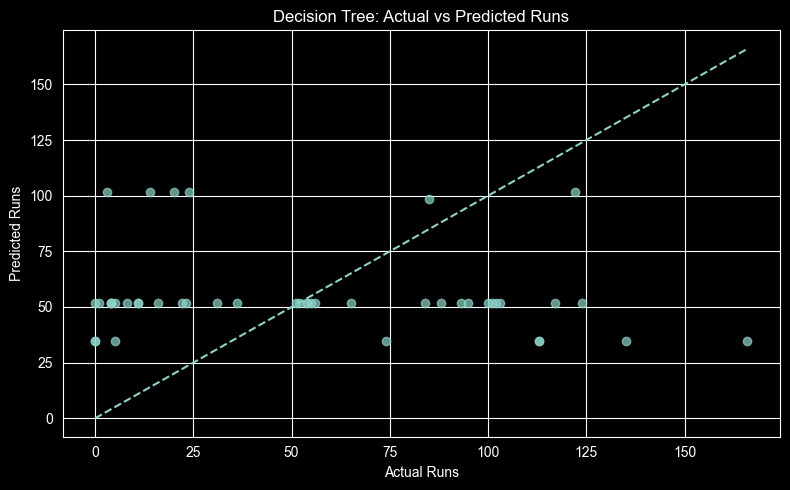

In [38]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, test_predictions, alpha=0.7)
lower = min(y_test.min(), test_predictions.min())
upper = max(y_test.max(), test_predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual Runs")
plt.ylabel("Predicted Runs")
plt.title("Decision Tree: Actual vs Predicted Runs")
plt.tight_layout()
plt.show()

In [40]:
decision_tree_result = pd.DataFrame([{
    "Model": "Decision Tree Regression",
    **best_params,
    "Validation_MAE": best_mae,
    "Test_MAE": test_mae,
    "Test_RMSE": test_rmse,
    "Test_R2": test_r2
}])


print(decision_tree_result)

                      Model  max_depth  min_samples_leaf  min_samples_split  \
0  Decision Tree Regression          2                 2                 10   

   Validation_MAE   Test_MAE  Test_RMSE   Test_R2  
0       34.472704  43.786346  52.454935 -0.295773  
